# Chapter 11 · Quasi-Monte Carlo: interactive demos

Companion to Chapter 11 of the [MFE 230D lecture notes](https://gennaroalberto.github.io/mfe230d-derivatives/notes.pdf).
Each section draws a figure with default settings, then an **Explore** cell lets you move the parameters.
The sliders need a running kernel: open the notebook in
[Google Colab](https://colab.research.google.com/github/GennaroAlberto/mfe230d-derivatives/blob/main/code/notebooks/11-quasi-monte-carlo.ipynb)
or in Jupyter after `pip install -e "code[dev]"`.

All generators (van der Corput, Halton, Sobol' with the Joe--Kuo direction numbers, and the scrambles) are
implemented from their definitions in `mfe230d.qmc`; nothing comes from `scipy.stats.qmc`.

In [1]:
# In Google Colab, this installs the course package from GitHub; elsewhere it does nothing.
import sys
if "google.colab" in sys.modules:
    %pip install -q "git+https://github.com/GennaroAlberto/mfe230d-derivatives#subdirectory=code"

import numpy as np
import matplotlib.pyplot as plt
from ipywidgets import interact, IntSlider, Dropdown
from scipy.special import ndtr

from mfe230d import qmc
from mfe230d.bs import TEST_CASE
from mfe230d.montecarlo import sine_product
from mfe230d.style import COBALT, GOLD, GREY, INK, PALETTE, use_style

GREEN = PALETTE[2]
P = tuple(TEST_CASE[k] for k in ("S", "K", "r", "y", "sigma"))   # S, K, r, y, sigma of the test case
use_style()

## 1. Point sets, nets and what randomisation keeps

The first $n=2^m$ Sobol' points form a $(t,m,d)$-net (Definition 11.7): every elementary interval of volume
$2^{t-m}$ holds exactly $2^t$ points. Choose the generator, two coordinates and the shape of the elementary
intervals ($2^{k_1}$ columns, $2^{m-t-k_1}$ rows, with $t$ the exact $t$-value of the projection, computed by the
rank criterion of Proposition 11.9). The title reports the exact star discrepancy of the projection and the
smallest and largest box counts. The nested scramble and the digital shift keep the net (Proposition 11.11(iii));
the random shift modulo 1 does not, and Halton and pseudo-random points are not nets in base 2.

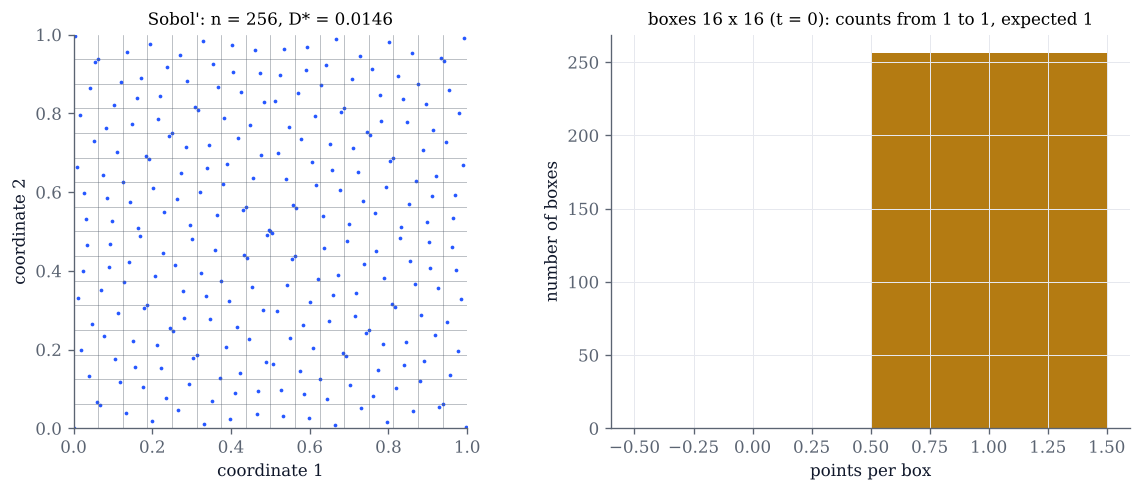

In [2]:
GENERATORS = ["Sobol'", "Sobol', nested scramble", "Sobol', digital shift", "Sobol', random shift",
              "Halton", "pseudo-random"]

def point_sets(generator="Sobol'", m=8, j=1, k=2, k1=4, seed=0):
    n, d = 2**m, max(j, k)
    if generator.startswith("Sobol'"):
        X = qmc.sobol_integers(n, d)
        if "nested" in generator:
            U = qmc.owen_scramble(X, seed=seed)
        elif "digital" in generator:
            U = qmc.digital_shift(X, seed=seed)
        elif "random shift" in generator:
            U = qmc.random_shift(X / 2.0**32, seed=seed)
        else:
            U = X / 2.0**32
    elif generator == "Halton":
        U = qmc.halton(n, d)
    else:
        U = np.random.default_rng(seed).random((n, d))
    Q = U[:, [j - 1, k - 1]]
    C = qmc.generator_matrices(d, m)
    t = qmc.t_value([C[j - 1], C[k - 1]]) if j != k else 0
    k1 = min(k1, m - t)
    k2 = m - t - k1
    Xi = np.minimum((Q * 2**32).astype(np.uint64), np.uint64(2**32 - 1))
    counts = qmc.elementary_counts(Xi, (k1, k2))
    fig, (ax, ax2) = plt.subplots(1, 2, figsize=(10, 4.2))
    for v in np.arange(1, 2**k1) / 2**k1:
        ax.axvline(v, color=GREY, lw=0.4, alpha=0.6)
    for v in np.arange(1, 2**k2) / 2**k2:
        ax.axhline(v, color=GREY, lw=0.4, alpha=0.6)
    ax.scatter(Q[:, 0], Q[:, 1], s=5, color=COBALT, lw=0)
    ax.set(xlim=(0, 1), ylim=(0, 1), aspect="equal", xlabel=f"coordinate {j}", ylabel=f"coordinate {k}",
           title=f"{generator}: n = {n}, D* = {qmc.star_discrepancy(Q):.4f}")
    ax.grid(False)
    ax2.hist(counts, bins=np.arange(counts.max() + 2) - 0.5, color=GOLD)
    ax2.set(xlabel="points per box", ylabel="number of boxes",
            title=f"boxes {2**k1} x {2**k2} (t = {t}): counts from {counts.min()} to {counts.max()}, "
                  f"expected {2**t}")
    plt.tight_layout()
    plt.show()

point_sets()

In [3]:
# Explore: compare the generators on the same boxes; try coordinates (15, 16) for Halton, or (20, 21) for Sobol'.
interact(point_sets,
         generator=Dropdown(options=GENERATORS, value="Sobol'", description="points"),
         m=IntSlider(value=8, min=4, max=11, continuous_update=False, description="m (n = 2^m)"),
         j=IntSlider(value=1, min=1, max=32, continuous_update=False, description="coordinate j"),
         k=IntSlider(value=2, min=1, max=32, continuous_update=False, description="coordinate k"),
         k1=IntSlider(value=4, min=0, max=11, continuous_update=False, description="k1 (columns)"),
         seed=IntSlider(value=0, min=0, max=50, continuous_update=False, description="seed"));

## 2. Smooth, kinked and discontinuous integrands

The Koksma--Hlawka inequality (Theorem 11.3) needs bounded variation; option payoffs composed with $N^{-1}$ do not
have it (Remark 11.4). Here three integrands with known integrals are priced with $n$ points in dimension $d$:
the smooth product of sines $\prod_j\frac\pi2\sin(\pi x_j)$, and, on $d$ monthly-spaced dates over one year,
the geometric Asian call (a kink, unbounded) and the geometric Asian digital paying $1$ if the geometric average
ends above the strike (a jump). The plot shows the root mean squared error over $R$ independent replicates for
plain Monte Carlo and for nested-scrambled Sobol' points, with the error of the deterministic Sobol' rule
(origin dropped, so that $N^{-1}$ is finite). The paths use the increments construction.

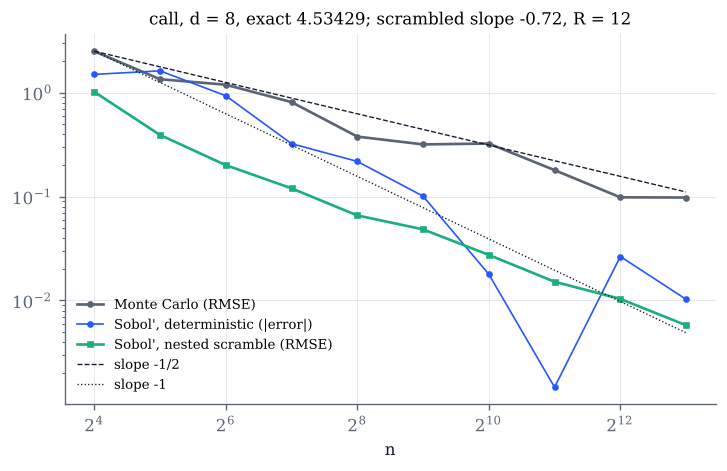

In [4]:
def integrand(name, d):
    if name == "smooth":
        return sine_product, 1.0
    t = qmc.asian_grid(d)
    S, K, r, y, sigma = P
    if name == "call":
        f = lambda U: qmc.asian_call_payoffs(qmc.to_normals(U), t, *P)[1]
        return f, qmc.geometric_asian_call(t, *P)
    mu, v = qmc.geometric_average_law(t, S, r, y, sigma)
    def f(U):
        Z = qmc.to_normals(U)
        logG = np.log(S) + (r - y - 0.5 * sigma**2) * t[1:].mean() + sigma * np.cumsum(np.sqrt(np.diff(t)) * Z, axis=1).mean(axis=1)
        return np.exp(-r * t[-1]) * (logG > np.log(K))
    return f, float(np.exp(-r * t[-1]) * ndtr((mu - np.log(K)) / np.sqrt(v)))

def integrands(name="call", d=8, R=12, log2_nmax=13, seed=1):
    f, exact = integrand(name, d)
    ns = 2 ** np.arange(4, log2_nmax + 1)
    mc = qmc.rqmc_nested(f, ns, d, R=R, sequence="random", seed=seed)
    sq = qmc.rqmc_nested(f, ns, d, R=R, method="owen", seed=seed)
    det = np.cumsum(f(qmc.sobol(ns[-1], d, start=1)))[ns - 1] / ns
    rm = lambda E: np.sqrt(np.mean((E - exact) ** 2, axis=0))
    fig, ax = plt.subplots(figsize=(7, 4))
    ax.plot(ns, rm(mc), color=GREY, marker="o", ms=3, label="Monte Carlo (RMSE)")
    ax.plot(ns, np.abs(det - exact), color=COBALT, marker="o", ms=3, lw=1, label="Sobol', deterministic (|error|)")
    ax.plot(ns, rm(sq), color=GREEN, marker="s", ms=3, label="Sobol', nested scramble (RMSE)")
    ref = rm(mc)[0] * np.sqrt(ns[0] / ns)
    ax.plot(ns, ref, color=INK, ls="--", lw=0.8, label="slope -1/2")
    ax.plot(ns, ref * np.sqrt(ns[0] / ns), color=INK, ls=":", lw=0.8, label="slope -1")
    slope = np.polyfit(np.log(ns[ns >= 256]), np.log(rm(sq)[ns >= 256]), 1)[0]
    ax.set(xscale="log", yscale="log", xlabel="n", title=f"{name}, d = {d}, exact {exact:.5f}; "
           f"scrambled slope {slope:.2f}, R = {R}")
    ax.set_xscale("log", base=2)
    ax.legend(fontsize=8)
    plt.show()

integrands()

In [5]:
# Explore: switch between the integrands at fixed d; then raise d. Where does the scrambled slope stay near -1?
interact(integrands,
         name=Dropdown(options=["smooth", "call", "digital"], value="call", description="integrand"),
         d=IntSlider(value=8, min=1, max=64, continuous_update=False, description="dimension d"),
         R=IntSlider(value=12, min=4, max=32, continuous_update=False, description="replicates R"),
         log2_nmax=IntSlider(value=13, min=8, max=15, continuous_update=False, description="log2 n max"),
         seed=IntSlider(value=1, min=0, max=50, continuous_update=False, description="seed"));

## 3. Replicates, error bars, and n that is not a power of two

Randomised QMC is unbiased, and the spread of $R$ independent replicates gives a Student interval
(Proposition 11.11(iv)). The left panel shows the $R$ replicate estimates for the product of sines in dimension $d$
and their interval. The right panel plots $n$ times the root mean squared error for **every** $n$: the extra
balance of the net, and the faster rate, exist only at $n=2^m$ (Remark 11.10).

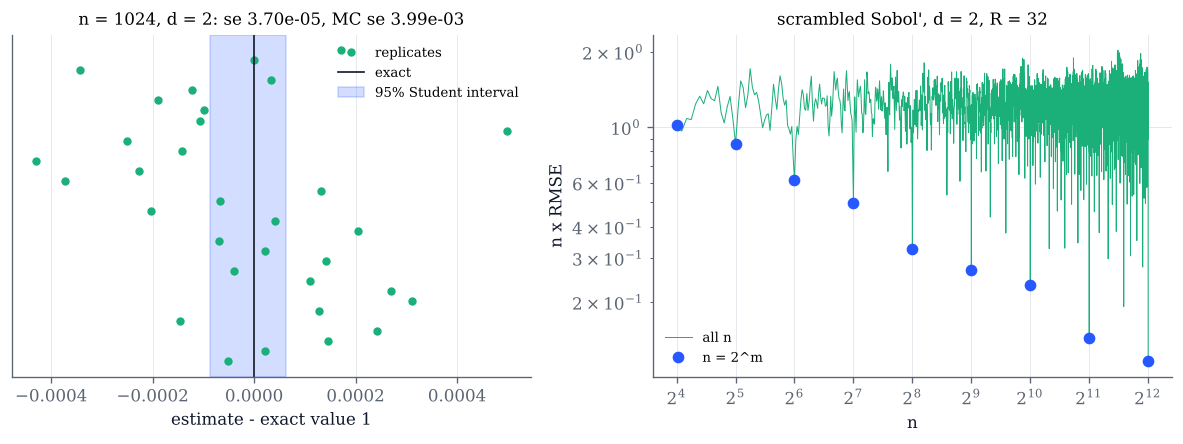

In [6]:
def replicates(d=2, R=32, log2_n=10, seed=3):
    n = 2**log2_n
    e = qmc.rqmc_estimate(sine_product, n, d, R=R, seed=seed)
    sig = np.sqrt((np.pi**2 / 8) ** d - 1)
    nall = np.arange(16, 2**12 + 1)
    E = qmc.rqmc_nested(sine_product, nall, d, R=R, seed=seed)
    fig, (ax, ax2) = plt.subplots(1, 2, figsize=(10, 3.8))
    ax.plot(e["replicates"] - 1, np.arange(R), "o", color=GREEN, ms=4, label="replicates")
    ax.axvline(0.0, color=INK, lw=1, label="exact")
    ax.axvspan(e["lo"] - 1, e["hi"] - 1, color=COBALT, alpha=0.2, label="95% Student interval")
    ax.set(xlabel="estimate - exact value 1", yticks=[], title=f"n = {n}, d = {d}: se {e['se']:.2e}, MC se {sig / np.sqrt(n * R):.2e}")
    ax.legend(fontsize=8)
    rmse = np.sqrt(np.mean((E - 1) ** 2, axis=0))
    ax2.plot(nall, nall * rmse, color=GREEN, lw=0.6, label="all n")
    p2 = 2 ** np.arange(4, 13)
    ax2.plot(p2, p2 * rmse[p2 - 16], "o", color=COBALT, label="n = 2^m")
    ax2.set(xscale="log", yscale="log", xlabel="n", ylabel="n x RMSE", title=f"scrambled Sobol', d = {d}, R = {R}")
    ax2.set_xscale("log", base=2)
    ax2.legend(fontsize=8)
    plt.tight_layout()
    plt.show()

replicates()

In [7]:
# Explore: how many replicates make the interval stable? How does the sawtooth change with d?
interact(replicates,
         d=IntSlider(value=2, min=2, max=10, continuous_update=False, description="dimension d"),
         R=IntSlider(value=32, min=4, max=64, continuous_update=False, description="replicates R"),
         log2_n=IntSlider(value=10, min=4, max=14, continuous_update=False, description="log2 n"),
         seed=IntSlider(value=3, min=0, max=50, continuous_update=False, description="seed"));

## 4. Effective dimension of the Asian call

The geometric Asian call depends on the normals only through $w\cdot Z$, so the share of its variance carried by
the first $k$ normals is $\kappa_g\big(\sum_{j\le k}w_j^2\big)$ (equation (11.7)); the vector $w$ depends on the
path construction. The left panel draws these exact shares for the three constructions, with pick-freeze estimates
for the arithmetic call (Lemma 11.12). The right panel measures what the shares predict: the standard deviation of
the arithmetic Asian call priced with $n$ scrambled Sobol' points, over $R$ scrambles, against plain Monte Carlo.

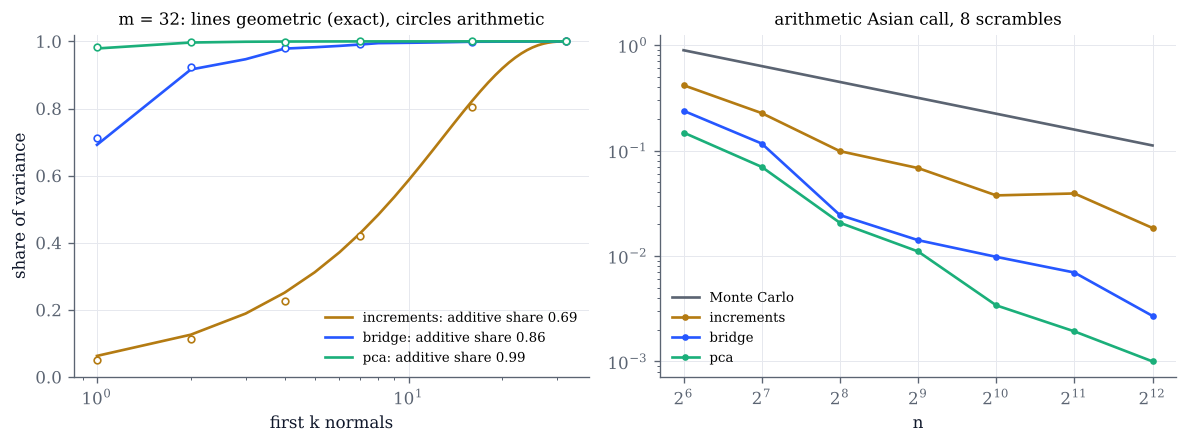

In [8]:
CONS = (("increments", GOLD), ("bridge", COBALT), ("pca", GREEN))

def effective(m=32, R=8, log2_nmax=12, seed=11):
    t = qmc.asian_grid(m)
    share = lambda c: qmc.lognormal_call_share(c, t, *P)
    ks = np.unique(np.geomspace(1, m, 6).astype(int))
    fig, (ax, ax2) = plt.subplots(1, 2, figsize=(10, 3.8))
    for me, color in CONS:
        Rsh = qmc.ridge_shares(qmc.average_direction(t, me), share)
        ax.plot(np.arange(1, m + 1), Rsh["truncation"], color=color, label=f"{me}: additive share {Rsh['additive']:.2f}")
        fA = lambda Z, me=me: qmc.asian_call_payoffs(Z, t, *P, method=me)[0]
        ax.plot(ks, qmc.pick_freeze_shares(fA, m, ks, n=2**13, seed=5), "o", color=color, mfc="white", ms=4)
    ax.set(xscale="log", ylim=(0, 1.02), xlabel="first k normals", ylabel="share of variance",
           title=f"m = {m}: lines geometric (exact), circles arithmetic")
    ax.legend(fontsize=8)
    ns = 2 ** np.arange(6, log2_nmax + 1)
    E = qmc.asian_rqmc(m, ns, R, seed, *P)
    Z = np.random.default_rng(seed).standard_normal((2**14, m))
    sigma = qmc.asian_call_payoffs(Z, t, *P)[0].std()
    ax2.plot(ns, sigma / np.sqrt(ns), color=GREY, label="Monte Carlo")
    for c, (me, color) in enumerate(CONS):
        ax2.plot(ns, E[:, :, c].std(axis=0, ddof=1), "o-", color=color, ms=3, label=me)
    ax2.set(xscale="log", yscale="log", xlabel="n", title=f"arithmetic Asian call, {R} scrambles")
    ax2.set_xscale("log", base=2)
    ax2.legend(fontsize=8)
    plt.tight_layout()
    plt.show()

effective()

In [9]:
# Explore: with few dates the constructions differ little; with many, the increments lose. Watch the additive share.
interact(effective,
         m=IntSlider(value=32, min=2, max=128, continuous_update=False, description="dates m"),
         R=IntSlider(value=8, min=4, max=32, continuous_update=False, description="scrambles R"),
         log2_nmax=IntSlider(value=12, min=8, max=15, continuous_update=False, description="log2 n max"),
         seed=IntSlider(value=11, min=0, max=50, continuous_update=False, description="seed"));

## Things to try

- In section 1, show coordinates 15 and 16 of the Halton points, then the same coordinates of the Sobol' points.
  Which boxes does the Halton projection leave empty? Then scramble the Sobol' points and check that every count
  stays at $2^t$, while the random shift modulo 1 breaks it.
- In section 2, compare the scrambled slope for the smooth integrand, the call and the digital at $d=2$ and at
  $d=32$. Which of the three loses most when $d$ grows, and why does the digital lose more than the call?
- In section 3, set $R=4$ and rerun with several seeds: how often does the interval miss the exact value?
- In section 4, set $m=2$ and $m=128$. For which $m$ does the choice of construction stop mattering, and how does
  that match the shares on the left?